In [8]:
# Load the basic and TF-IDF ingredient features for K-Means clustering.
import pandas as pd
import matplotlib.pyplot as plt
from scipy.sparse import load_npz
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
X_basic = pd.read_csv("ingredients_basic.csv")
X_tfidf = load_npz("ingredients_tfidf.npz")

print("Basic Features:", X_basic.shape)
print("TF-IDF Features:", X_tfidf.shape)


Basic Features: (2724, 11)
TF-IDF Features: (2724, 7316)


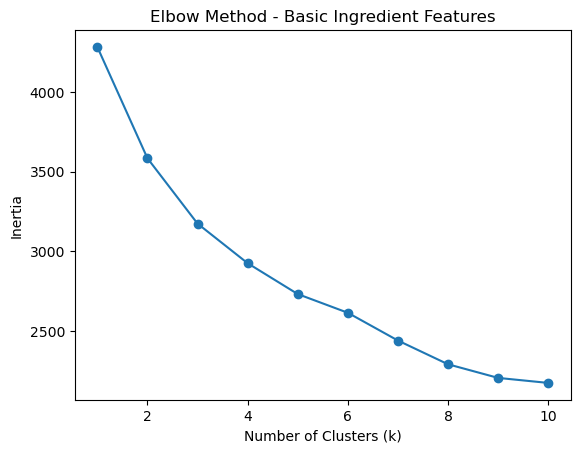

In [9]:
# Apply the Elbow Method to find a suitable number of clusters using basic ingredient features.
inertia_basic = []
for k in range(1, 11):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_basic)
    inertia_basic.append(km.inertia_)

plt.plot(range(1, 11), inertia_basic, marker='o')
plt.title("Elbow Method - Basic Ingredient Features")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia")
plt.show()


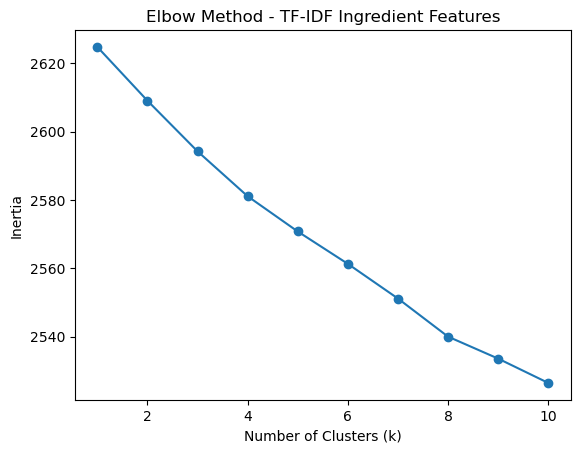

In [10]:
# Apply the Elbow Method using TF-IDF ingredient features.
inertia_tfidf = []
for k in range(1, 11):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_tfidf)
    inertia_tfidf.append(km.inertia_)

plt.plot(range(1, 11), inertia_tfidf, marker='o')
plt.title("Elbow Method - TF-IDF Ingredient Features")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia")
plt.show()


In [11]:
# Calculate Silhouette Scores for K-Means using the 11 basic ingredient features.
scores_basic = []
for k in range(2, 11):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_basic)
    score = silhouette_score(X_basic, labels, sample_size=500, random_state=42)
    scores_basic.append(score)
    print("k =", k, "Silhouette Score =", round(score, 3))


k = 2 Silhouette Score = 0.179
k = 3 Silhouette Score = 0.184
k = 4 Silhouette Score = 0.178
k = 5 Silhouette Score = 0.195
k = 6 Silhouette Score = 0.189
k = 7 Silhouette Score = 0.219
k = 8 Silhouette Score = 0.228
k = 9 Silhouette Score = 0.237
k = 10 Silhouette Score = 0.225


In [12]:
# Calculate Silhouette Scores for K-Means using TF-IDF ingredient features.
scores_tfidf = []
for k in range(2, 11):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_tfidf)

    score = silhouette_score(X_tfidf, labels, sample_size=500, random_state=42)

    scores_tfidf.append(score)

    print("k =", k, "Silhouette Score =", round(score, 3))


k = 2 Silhouette Score = 0.004
k = 3 Silhouette Score = 0.004
k = 4 Silhouette Score = 0.005
k = 5 Silhouette Score = 0.006
k = 6 Silhouette Score = 0.007
k = 7 Silhouette Score = 0.008
k = 8 Silhouette Score = 0.009
k = 9 Silhouette Score = 0.01
k = 10 Silhouette Score = 0.01


In [13]:
# Apply K-Means with 9 clusters and count products in each cluster.

kmeans_basic = KMeans(n_clusters=9, random_state=42, n_init=10)

basic_labels = kmeans_basic.fit_predict(X_basic)

print("Products in Each Cluster:")
print(pd.Series(basic_labels).value_counts().sort_index())


Products in Each Cluster:
0    248
1    306
2    463
3    276
4    491
5    281
6    324
7    132
8    203
Name: count, dtype: int64


In [14]:
# Calculate the average ingredient feature values for each cluster.
cluster_features = X_basic.copy()
cluster_features["Cluster"] = basic_labels
cluster_summary = cluster_features.groupby("Cluster").mean().round(2)
display(cluster_summary)


,has_niacinamide,has_salicylic_acid,has_zinc,has_clay,has_heavy_oil_butter,has_ceramide,has_hyaluronic,has_squalane,has_fragrance,has_alcohol_denat,has_essential_oil
Cluster,,,,,,,,,,,
0,0.17,0.06,0.11,0.03,0.21,0.11,1.00,0.17,1.00,0.00,0.05
1,0.10,0.15,0.05,0.16,0.20,0.07,0.03,0.10,0.01,0.22,1.00
2,0.12,0.12,0.05,0.10,0.00,0.05,0.00,0.00,0.00,0.11,0.00
3,0.13,0.05,0.02,0.05,0.75,0.11,0.00,0.65,0.08,0.09,0.08
4,0.20,0.10,0.04,0.03,0.27,0.16,1.00,0.00,0.00,0.00,0.16
5,0.16,0.09,0.05,0.02,0.48,0.16,1.00,1.00,0.10,0.08,0.22
6,0.10,0.07,0.09,0.10,0.22,0.02,0.00,0.09,1.00,0.00,0.10
7,0.08,0.13,0.13,0.08,0.17,0.01,0.00,0.08,1.00,1.00,0.09
8,0.14,0.15,0.12,0.05,0.23,0.07,1.00,0.16,0.60,1.00,0.26


In [15]:
# Display three skincare products from each cluster to inspect the groups.
df = pd.read_csv("skincare_clean.csv")

df["Cluster"] = basic_labels

sample_products = df.groupby("Cluster").head(3)

display(sample_products[["Cluster", "brand", "name", "category"]].sort_values("Cluster"))


,Cluster,brand,name,category
91,0,Blissful,Hyaluronic acid,Serum
117,0,Algenist,ELEVATE Advanced Lift Contouring Cream,Moisturizer
87,0,Blissful,Water Cream,Moisturizer
112,1,Algenist,Blue Algae Vitamin C Dark Spot Correcting Peel,Treatment
95,1,Algenist,GENIUS Sleeping Collagen Moisturizer,Moisturizer
120,1,Algenist,Algae Peptide Regenerative Moisturizer,Moisturizer
0,2,The Ordinary,Balancing & Clarifying Serum,Serum
1,2,The Ordinary,GF 15% Solution,Serum
2,2,The Ordinary,Multi-Antioxidant Radiance Serum,Treatment
17,3,The Ordinary,Granactive Retinoid 5% in Squalane,Serum


In [16]:
# Check the percentage of products suitable for each skin type in every cluster.
skin_cols = ["tag_dry", "tag_oily", "tag_combination",
             "tag_normal", "tag_sensitive", "tag_acne_prone"]

labeled_clusters = df[df["has_skin_label"] == 1]

skin_summary = labeled_clusters.groupby("Cluster")[skin_cols].mean() * 100

display(skin_summary.round(1))


,tag_dry,tag_oily,tag_combination,tag_normal,tag_sensitive,tag_acne_prone
Cluster,,,,,,
0,75.0,52.6,80.2,79.3,32.8,16.4
1,53.7,67.7,77.1,75.1,38.8,42.3
2,56.1,61.7,73.5,73.5,37.6,40.8
3,74.3,50.7,72.9,78.5,38.9,13.2
4,69.7,58.7,74.2,78.2,38.4,21.0
5,78.7,52.9,80.9,81.6,38.2,13.2
6,72.4,64.3,82.7,83.7,40.3,22.4
7,72.4,69.0,89.7,87.4,31.0,18.4
8,69.7,59.7,79.0,79.8,41.2,18.5


In [17]:
# Count how many labeled skincare products belong to each cluster.
labeled_counts = labeled_clusters.groupby("Cluster").size()

print("Labeled Products in Each Cluster:")
print(labeled_counts)

print("\nTotal Labeled Products:", len(labeled_clusters))


Labeled Products in Each Cluster:
Cluster
0    116
1    201
2    287
3    144
4    271
5    136
6    196
7     87
8    119
dtype: int64

Total Labeled Products: 1557


In [18]:
# Save the trained K-Means model and skincare products with their cluster numbers.
import joblib

joblib.dump(kmeans_basic, "kmeans_basic.pkl")

df.to_csv("skincare_clustered.csv", index=False)

print("K-Means model saved successfully!")
print("Clustered skincare dataset saved successfully!")
print("Total Products:", len(df))
print("Total Clusters:", df["Cluster"].nunique())


K-Means model saved successfully!
Clustered skincare dataset saved successfully!
Total Products: 2724
Total Clusters: 9


### Conclusion

In this phase, K-Means clustering was applied to 2,724 skincare products using two different ingredient representations:

- **Basic features:** 11 selected ingredient indicators.
- **TF-IDF features:** 7,316 ingredient features extracted from complete ingredient lists.

The Elbow Method and Silhouette Score were used to evaluate clustering performance.

The basic-feature model achieved its highest tested Silhouette Score of **0.237 at k = 9**, while the TF-IDF model achieved a maximum tested score of approximately **0.010**.

Therefore, K-Means with **9 clusters using basic ingredient features** was selected for the current SkinMatch implementation.

The clusters represent different ingredient patterns, such as products containing hyaluronic acid, squalane, fragrance, and essential oils.

However, the Silhouette Score indicates relatively weak cluster separation. These groups will be used for ingredient-based analysis rather than as direct predictions of skin-type suitability.

The trained K-Means model and clustered dataset were saved for use in the SkinMatch recommendation system.